In [1]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
from astroquery.gaia import Gaia
import tqdm
from astropy.table import join
from scipy.optimize import root_scalar
from astroquery.simbad import Simbad

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [11]:
# Import raw SRSC data

In [2]:
srsc_id_table = Table.read('data/2026.01.16_12_07_51_SRSC_Static.csv')
srsc_radio_table = Table.read('data/2026.01.16_12_07_51_SRSC_Var_alldetections.csv')

In [3]:
srsc_id_table

Identifier,Simbad_ID,GaiaDR3_ID,TYCHO_ID,2MASS_ID,GCVS_ID,HIP_ID,UCAC4_ID,Archival_Survey,Archival_ID,Archival_epoch,Archival_ra,Archival_ra_err,Archival_dec,Archival_dec_err,Archival_ra_hms,Archival_dec_dms,Archival_parallax,Archival_parallax_err,Archival_pmra,Archival_pmra_err,Archival_pmdec,Archival_pmdec_err,Radio_multiple,Search_method_bin,1RXS_ID,TIC_ID,WISE_ID,AllWISE_ID,CNS5_ID,Stripped_Identifier,Stripped_Archival_ID
str10,str31,str28,str15,str23,str14,str10,str16,str39,str28,str19,float64,float64,float64,float64,str17,str19,float64,float64,float64,float64,float64,float64,float64,int64,str21,str14,str25,str25,str9,str9,str26
SRSC 00000,CPD-62 4126,Gaia DR3 5853502492753436416,TYC 9010-2749-1,2MASS J14270430-6246553,--,--,UCAC4 137-115021,GaiaDR3,Gaia DR3 5853502492753436416,J2016,216.767919155244,6e-06,-62.782098179545,9e-06,14:27:04,-62:46:55.553446362,1.53,0.01,-3.841,0.007,-5.44,0.01,0.0,18,1RXS J142704.5-624659,TIC 385279385,--,--,--,SRSC00000,GaiaDR35853502492753436416
SRSC 00001,TYC 9078-815-1,Gaia DR3 6438561254116213760,TYC 9078-815-1,2MASS J19040331-6400142,--,--,UCAC4 130-173182,GaiaDR3,Gaia DR3 6438561254116213760,J2016,286.013875552226,8e-06,-64.00397308781,9e-06,19:04:03,-64:00:14.303116116,2.38,0.01,6.74,0.01,-4.68,0.01,0.0,18,1RXS J190403.3-640011,--,--,--,--,SRSC00001,GaiaDR36438561254116213760
SRSC 00002,SCR J2241-6119A,Gaia DR3 6406967509044836096,--,2MASS J22414436-6119311,--,--,UCAC4 144-211738,GaiaDR3,Gaia DR3 6406967509044836096,J2016,340.436272395047,8e-06,-61.325706059717,1e-05,22:41:45,-61:19:32.541814980,35.2,0.01,150.4,0.01,-87.89,0.01,0.0,18,--,TIC 232064182,WISE J224144.56-611932.0,--,--,SRSC00002,GaiaDR36406967509044836096
SRSC 00003,CD-30 6530,Gaia DR3 5640708647248169600,TYC 7136-2264-1,2MASS J08355977-3042306,--,--,UCAC4 297-048519,GaiaDR3,Gaia DR3 5640708647248169600,J2016,128.998712548091,8e-06,-30.70858670455,1e-05,08:36:00,-30:42:30.91213638,15.7,0.01,-64.11,0.01,-14.3,0.01,0.0,18,1RXS J083559.7-304226,TIC 11663272,--,--,--,SRSC00003,GaiaDR35640708647248169600
SRSC 00004,CD-49 451,Gaia DR3 4917782741272766592,TYC 8043-814-1,2MASS J01372081-4911443,--,HIP 7554,UCAC4 205-001600,GaiaDR3,Gaia DR3 4917782741272766592,J2016,24.34012397651,1e-05,-49.195143947004,1e-05,01:37:22,-49:11:42.51820921,45.12,0.01,496.1,0.01,116.1,0.01,0.0,18,1RXS J013721.1-491144,TIC 158624542,--,WISEA J013721.34-491143.1,CNS5 406,SRSC00004,GaiaDR34917782741272766592
SRSC 00005,ATO J183.5330+47.2673,Gaia DR3 1545247048904161664,--,2MASS J12140814+4716038,--,--,UCAC4 687-053931,GaiaDR3,Gaia DR3 1545247048904161664,J2016,183.532979271787,1e-05,47.267364915243,1e-05,12:14:08,+47:16:02.51369487,25.76,0.02,-137.2,0.01,-72.58,0.01,0.0,16,--,TIC 138182259,--,WISEA J121407.98+471602.9,--,SRSC00005,GaiaDR31545247048904161664
SRSC 00006,HD 102982,Gaia DR3 5368777294028600448,TYC 8228-2739-1,2MASS J11510909-5152323,--,--,UCAC4 191-064625,GaiaDR3,Gaia DR3 5368777294028600448,J2016,177.787504285457,1e-05,-51.876071495961,1e-05,11:51:09,-51:52:33.85738546,18.8,0.02,-57.34,0.02,-83.67,0.01,0.0,18,1RXS J115108.5-515223,TIC 94637805,--,--,--,SRSC00006,GaiaDR35368777294028600448
SRSC 00007,2MASS J11414215-6521298,Gaia DR3 5236539580341818624,--,2MASS J11414215-6521298,--,--,UCAC4 124-048667,GaiaDR3,Gaia DR3 5236539580341818624,J2016,175.425221260026,1e-05,-65.358320600806,1e-05,11:41:42,-65:21:29.95416290,9.92,0.02,-40.18,0.02,-4.38,0.02,0.0,18,1RXS J114142.1-652128,TIC 321772880,--,--,--,SRSC00007,GaiaDR35236539580341818624
SRSC 00008,Gaia DR3 6090676737160646528,Gaia DR3 6090676737160646528,--,--,--,--,--,GaiaDR3,Gaia DR3 6090676737160646528,J2016,211.790382522137,1e-05,-50.034311567705,1e-05,14:07:10,-50:02:03.52164374,10.99,0.02,-54.59,0.02,-46.85,0.02,0.0,16,--,--,--,--,--,SRSC00008,GaiaDR36090676737160646528


In [4]:
srsc_radio_table

index,Identifier,Search_method,Crossmatch_radius_arcsec,Radio_optical_sep_arcsec,Radio_component_id,Radio_SBID,Radio_starttime_mjd,Radio_endtime_mjd,Radio_starttime_isot,Radio_endtime_isot,Radio_exptime_s,Radio_ra,Radio_dec,Radio_ra_err,Radio_dec_err,Radio_ra_hms,Radio_dec_dms,Radio_freq_MHz,Radio_I_flux_peak,Radio_I_flux_peak_err,Radio_I_flux_int,Radio_I_flux_int_err,Radio_maj_axis,Radio_min_axis,Radio_pos_angle,Radio_maj_axis_err,Radio_min_axis_err,Radio_survey,Radio_I_measurementType,Radio_V_measurementType,Radio_V_flux_peak,Radio_V_flux_peak_err,Radio_V_flux_int,Radio_V_flux_int_err,Radio_telescope,Radio_local_V_RMS,Radio_local_I_RMS,Reference,unique_obs_id
int64,str10,str15,float64,float64,str37,str185,float64,float64,str23,str23,str18,float64,float64,float64,float64,str17,str18,str13,float64,float64,float64,float64,float64,float64,float64,float64,float64,str16,str13,str13,float64,float64,float64,float64,str19,float64,str18,str153,str185
1899,SRSC 00000,LightCurve,2.0,1.1,SB22350_component_2094a,SB22350_RACS_1424-60,59246.87228009,59246.88263889,2021-02-01T20:56:05.000,2021-02-01T21:11:00,895.0,216.7673,-62.7821,2.0,2.0,14:27:04.1,-62:46:55,1367.5,1.6,0.3,1.6,0.5,9.0,8.0,170.91,2.0,1.0,--,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.28,SRSCv1.0,SB22350_RACS_1424-60
1909,SRSC 00000,LightCurve,2.0,1.6,SB45665_component_4457a,SB45665_VAST_1404-62,59902.05111111,59902.05940972,2022-11-19T01:13:36.000,2022-11-19T01:25:33,717.0,216.767,-62.7823,2.0,2.0,14:27:04.1,-62:46:56,887.5,1.6,0.2,1.8,0.3,19.0,11.0,134.44,2.0,1.0,--,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.21,SRSCv1.0,SB45665_VAST_1404-62
1910,SRSC 00000,LightCurve,2.0,0.7,SB45667_component_4705a,SB45667_VAST_1453-62,59902.06976852,59902.07806713,2022-11-19T01:40:28.000,2022-11-19T01:52:25,717.0,216.7676,-62.7823,2.0,2.0,14:27:04.2,-62:46:56,887.5,1.4,0.2,1.7,0.4,16.0,15.0,86.21,2.0,2.0,--,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.24,SRSCv1.0,SB45667_VAST_1453-62
1914,SRSC 00000,ROSAT_Stellar,2.8,0.7,SB45821_component_4152b,SB45821_EMU_1442-64,59907.98746528,59908.40425926,2022-11-24T23:41:57.000,2022-11-25T09:42:08,36011.0,216.7681,-62.7819,2.0,2.0,14:27:04.3,-62:46:55,943.5,0.64,0.03,0.74,0.05,17.5,15.0,133.57,0.7,0.7,10-11hour,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.03,SRSCv1.0,SB45821_EMU_1442-64
1912,SRSC 00000,LightCurve,2.0,2.2,SB47236_component_4433a,SB47236_VAST_1404-62,59964.86481481,59964.87321759,2023-01-20T20:45:20.000,2023-01-20T20:57:26,726.0,216.7684,-62.7827,2.0,2.0,14:27:04.4,-62:46:58,887.5,1.4,0.2,1.7,0.4,20.0,11.0,135.82,2.0,2.0,--,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.24,SRSCv1.0,SB47236_VAST_1404-62
1913,SRSC 00000,StokesV,--,--,SB47240_component_3629a,SB47240_VAST_1453-62,59964.90674769,59964.90674769,2023-01-20T21:45:43.000,2023-01-20T21:45:43,726.0,216.7677,-62.783,--,--,14:27:04.24,-62:46:59,887.5,2.1,0.2,2.8,0.4,--,--,--,--,--,VAST 23e,Detection,Detection,1.3,--,1.9,--,ASKAP,--,0.29,10.1093/mnras/stab299,SB47240_VAST_1453-62
1908,SRSC 00000,LightCurve,2.0,1.2,SB50301_component_4182a,SB50301_VAST_1453-62,60097.53744213,60097.54572917,2023-06-02T12:53:55.000,2023-06-02T13:05:51,716.0,216.7685,-62.7823,2.0,2.0,14:27:04.4,-62:46:56,887.5,1.6,0.3,1.5,0.5,17.0,11.0,123.01,3.0,2.0,--,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.26,SRSCv1.0,SB50301_VAST_1453-62
1911,SRSC 00000,ROSAT_Stellar,2.7,0.6,SB51091_component_4642a,SB51091_VAST_1453-62,60129.45053241,60129.45883102,2023-07-04T10:48:46.000,2023-07-04T11:00:43,717.0,216.7675,-62.7821,2.0,2.0,14:27:04.2,-62:46:56,887.5,1.3,0.3,1.2,0.5,15.0,11.0,164.89,3.0,2.0,00-01hour,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.25,SRSCv1.0,SB51091_VAST_1453-62
1906,SRSC 00000,LightCurve,2.0,2.5,SB51522_component_4617a,SB51522_VAST_1453-62,60146.41688657,60146.42528935,2023-07-21T10:00:19.000,2023-07-21T10:12:25,726.0,216.7664,-62.782,2.0,2.0,14:27:03.9,-62:46:55,887.5,1.4,0.2,1.6,0.4,22.0,10.0,141.85,2.0,2.0,--,Detection,NoMeasurement,--,--,--,--,ASKAP,--,0.25,SRSCv1.0,SB51522_VAS

1. We need Gaia colours to make a CMD, so we need to remove any sources that don't have a GAIA ID. Possible that Gaia data exists for these stars but just wasn't on SIMBAD, so store them for later.

In [5]:
srsc_gaia_sources = srsc_id_table[~srsc_id_table['GaiaDR3_ID'].mask]
srsc_non_gaia_sources = srsc_id_table[srsc_id_table['GaiaDR3_ID'].mask]

In [6]:
srsc_non_gaia_sources

Identifier,Simbad_ID,GaiaDR3_ID,TYCHO_ID,2MASS_ID,GCVS_ID,HIP_ID,UCAC4_ID,Archival_Survey,Archival_ID,Archival_epoch,Archival_ra,Archival_ra_err,Archival_dec,Archival_dec_err,Archival_ra_hms,Archival_dec_dms,Archival_parallax,Archival_parallax_err,Archival_pmra,Archival_pmra_err,Archival_pmdec,Archival_pmdec_err,Radio_multiple,Search_method_bin,1RXS_ID,TIC_ID,WISE_ID,AllWISE_ID,CNS5_ID,Stripped_Identifier,Stripped_Archival_ID
str10,str31,str28,str15,str23,str14,str10,str16,str39,str28,str19,float64,float64,float64,float64,str17,str19,float64,float64,float64,float64,float64,float64,float64,int64,str21,str14,str25,str25,str9,str9,str26
SRSC 00175,HD 165590A,--,TYC 1566-747-1,--,V* V772 Her,HIP 88637A,--,TYCHO,TYC 1566-747-1,J2000,271.457229,--,21.44599,--,18:05:49.7350,+21:26:45.56,--,--,-29.2,--,-40.3,--,2.0,2,--,--,--,--,--,SRSC00175,TYC1566-747-1
SRSC 00200,* alf Gem,--,--,2MASS J07343598+3153184,--,HIP 36850,UCAC4 610-041019,HIP,HIP 36850,J1991.25,113.65001968,0.003,31.88863511,0.003,07:34:36.0047232,+31:53:19.086396,64.0,4.0,-191.0,4.0,-145.0,3.0,0.0,18,--,TIC 239187687,--,--,CNS5 1879,SRSC00200,HIP36850
SRSC 00202,AX J1600.9-5142,--,--,2MASS J16005047-5142449,--,--,--,WolfRayet,WR 70-16,J2016,240.210375,--,-51.712583,--,16:00:50.4900,-51:42:45.30,--,--,--,--,--,--,0.0,2,1RXS J160045.0-514307,TIC 274741039,WISE J160050.53-514245.2,WISEA J160050.46-514245.5,--,SRSC00202,WR70-16
SRSC 00208,StKM 1-2018,--,--,2MASS J22332264-0936537,--,--,UCAC4 402-129514,UCAC4,UCAC4 402-129514,J2000,338.3444136,0.02,-9.614927,0.01,22:33:22.659264,-09:36:53.73720,--,--,145.0,2.0,6.0,1.0,1.0,18,1RXS J223323.6-093704,TIC 250976348,--,--,--,SRSC00208,UCAC4402-129514
SRSC 00209,[KSF2015] 1256-1483A,--,--,--,--,--,--,WolfRayet,WR 98-2,J2016,265.247292,--,-32.189528,--,17:40:59.3500,-32:11:22.30,--,--,--,--,--,--,0.0,2,--,--,--,--,--,SRSC00209,WR98-2
SRSC 00216,V* V503 Hya,--,TYC 224-1290-1,2MASS J08491980+0552298,V* V503 Hya,--,UCAC4 480-045324,GaiaDR2,Gaia DR2 582882278166763648,J2015.5,132.3323743953,4e-05,5.874897840104,3e-05,08:49:20,+05:52:29.63222437,5.47,0.06,-42.42,0.09,2.77,0.06,0.0,2,1RXS J084919.7+055234,TIC 262588562,--,--,--,SRSC00216,GaiaDR2582882278166763648
SRSC 00218,* gam02 Vel,--,TYC 8140-6533-1,2MASS J08093195-4720115,V* gam02 Vel,HIP 39953,UCAC4 214-020008,HIP,HIP 39953,J1991.25,122.38314733,0.0003,-47.33661168,0.0003,08:09:31.95535920,-47:20:11.8020480,2.9,0.3,-6.1,0.3,10.4,0.3,0.0,2,1RXS J080933.7-472027,TIC 354825513,--,--,--,SRSC00218,HIP39953
SRSC 00226,PM J19515-3510,--,--,2MASS J19513587-3510375,--,--,UCAC4 275-205750,UCAC4,UCAC4 275-205750,J2000,297.89948,0.03,-35.1771659,0.02,19:51:35.875200,-35:10:37.79724,--,--,0.0,50.0,0.0,50.0,1.0,18,1RXS J195135.9-351029,TIC 218911792,WISE J195136.21-351036.8,--,--,SRSC00226,UCAC4275-205750
SRSC 00301,RX J0419.2-7120,--,--,2MASS J04191354-7121111,--,--,UCAC4 094-004239,UCAC4,UCAC4 094-004239,J2000,64.80626,0.03,-71.3531289,0.03,04:19:13.502400,-71:21:11.26404,--,--,-52.0,2.0,-46.0,2.0,1.0,18,1RXS J041916.1-712059,TIC 29779873,WISE J041913.41-712111.7,--,--,SRSC00301,UCAC4094-004239


2. To make a colour magnitude diagram we need:
    - Colour --> Gaia bp - rp
    - Magnitude --> Gaia G band flux & parallax

So we just need to query Gaia with a list of our Gaia IDs

In [7]:
gaia_ids_str = srsc_gaia_sources['GaiaDR3_ID']
gaia3_ids_str = gaia_ids_str[np.char.startswith(gaia_ids_str, 'Gaia DR3')] # Using only DR3 Data
gaia_ids = [int(gid.lstrip('Gaia DR3 ')) for gid in gaia3_ids_str]

In [8]:
len(gaia_ids)

1795

In [9]:
gaiadr3_table = Gaia.load_table('gaiadr3.gaia_source')

# Converting IDs to a string format
ids_str = ','.join(map(str, gaia_ids))

query = f"""
SELECT gs.source_id,
       gs.phot_g_mean_mag,
       gs.bp_rp,
       ap.teff_gspphot,
       ap.logg_gspphot,
       dist.r_med_geo,
       dist.r_lo_geo,
       dist.r_hi_geo
FROM gaiadr3.gaia_source AS gs
JOIN gaiadr3.astrophysical_parameters AS ap
     ON gs.source_id = ap.source_id
JOIN external.gaiaedr3_distance AS dist
     ON gs.source_id = dist.source_id
WHERE gs.source_id IN ({ids_str})
AND dist.r_med_geo IS NOT NULL
AND dist.r_lo_geo IS NOT NULL
AND dist.r_hi_geo IS NOT NULL
AND ap.teff_gspphot IS NOT NULL
AND ap.logg_gspphot IS NOT NULL;
"""

job = Gaia.launch_job_async(query)
srsc_stars = job.get_results()

In [ ]:
srsc_stars.write('data/gaia_bj_data.csv', format='csv', overwrite=True)

In [10]:
# Just read it in next time instead of redoing a lengthy query
srsc_stars = Table.read('data/gaia_bj_data.csv')

In [18]:
srsc_stars['abs_mag'] = srsc_stars['phot_g_mean_mag'] -  5 * np.log10(srsc_stars['r_med_geo']) + 5

In [19]:
len(srsc_stars)

847

Next we need to get a definition of solar-like stars. There are a variety of definitions for solar-like stars. The ones I am going to use are tempeartures between 5100 and 6000 (~~Shen 2024~~, **Maehara 2012**) and a B-V colour between 0.59 and 0.69 (de Stroebel 1996). To get B-V colours to Gaia BP-RP colours, we need to go through G band colours (Riello 2021). We also require logg > 4, as also outlined in Maehara 2012

In [20]:
def gv_from_bv(bv):
    return (-0.04749
            -0.0124*bv
            -0.2901*bv**2
            +0.02008*bv**3)

def gv_from_bprp(x):
    return (-0.02704
            +0.01424*x
            -0.2156*x**2
            +0.01426*x**3)

def bv_to_bprp(bv):
    target = gv_from_bv(bv)
    f = lambda x: gv_from_bprp(x) - target
    return root_scalar(f, bracket=[-0.5, 4], method='brentq').root

In [21]:
lower_bprp = bv_to_bprp(0.59)
upper_bprp = bv_to_bprp(0.69)

Note a slight discrepancy. The BP-RP value of 0.82 from Golovin 2023 isnt aligned with the converted BP-RP of 0.88 that we get when we use B-V = 0.65. These are both within the range we get from our lower and upper values.

In [16]:
print(lower_bprp, upper_bprp)

0.8174063024116834 0.9264687273964255


So now that we have ways to cut our sample out, lets select and plot any stars that we deem 'solar-like' and see 1) what sample size we are left with and 2) where they lie in the CMD.

In [23]:
# Select solar-like temperatures
mask = (srsc_stars['teff_gspphot'] > 5100) & (srsc_stars['teff_gspphot'] < 6000)
solar_temp_stars = srsc_stars[mask]

In [24]:
# Select solar-like colours
mask = (solar_temp_stars['bp_rp'] > lower_bprp) & (solar_temp_stars['bp_rp'] < upper_bprp)
solar_colour_stars = solar_temp_stars[mask]

In [25]:
# Select solar-like surface gravity
mask = (solar_colour_stars['logg_gspphot'] >= 4)
solar_like_stars = solar_colour_stars[mask]

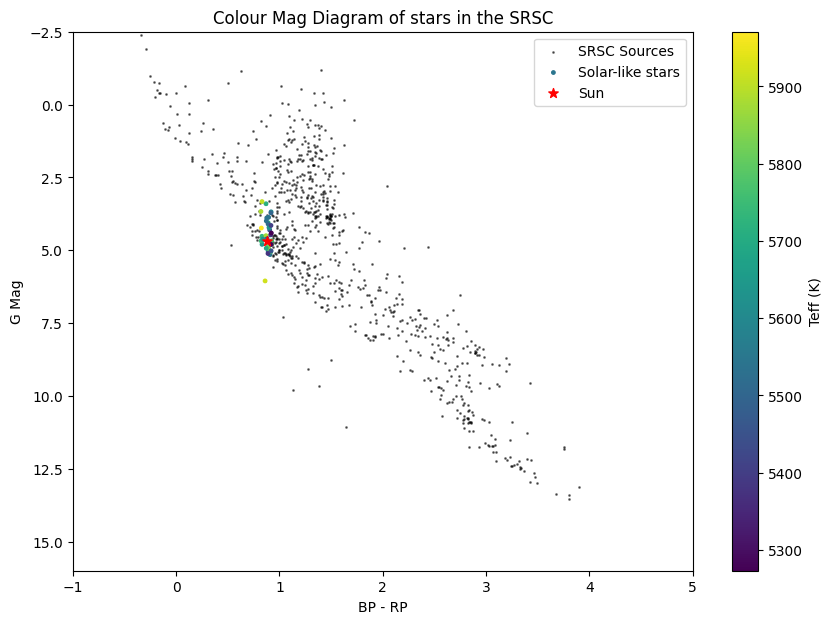

In [16]:
plt.figure(figsize=(10,7))
plt.scatter(srsc_stars['bp_rp'], srsc_stars['abs_mag'], s=1, c='black', alpha = 0.5, label='SRSC Sources')
sc = plt.scatter(solar_like_stars['bp_rp'], solar_like_stars['abs_mag'], s=6, c=solar_like_stars['teff_gspphot'], cmap='viridis', label = 'Solar-like stars')


plt.scatter(0.88, 4.67, c='red', marker='*', s=50, label='Sun') # Golovin 2023

plt.ylim(16, -2.5)
plt.xlim(-1, 5)
plt.xlabel('BP - RP')
plt.ylabel('G Mag')
plt.title('Colour Mag Diagram of stars in the SRSC')

cbar = plt.colorbar(sc)
cbar.set_label('Teff (K)')

plt.legend()
plt.show()

In [26]:
solar_like_stars.sort('abs_mag')
solar_like_stars

source_id,phot_g_mean_mag,bp_rp,teff_gspphot,logg_gspphot,r_med_geo,r_lo_geo,r_hi_geo,abs_mag
int64,float64,float64,float64,float64,float64,float64,float64,float64
6633474669669267712,8.335362434387207,0.8312587738037109,5904.27490234375,4.039100170135498,100.24916076660156,100.01433563232422,100.45816802978516,3.3299587062782052
4043524762244704000,9.039679527282715,0.8697547912597656,5716.19140625,4.03439998626709,133.99671936035156,133.6367950439453,134.34104919433594,3.4042086989339584
2800343793960754304,10.135481834411621,0.8207502365112305,5881.96826171875,4.169600009918213,196.45445251464844,195.5602264404297,197.16769409179688,3.66917245308
2210120493272273920,8.434609413146973,0.9191970825195312,5599.9443359375,4.0644001960754395,89.22227478027344,89.10758972167969,89.37097930908203,3.6822429548033426
6554844401276275712,8.329093933105469,0.9174795150756836,5499.30517578125,4.0767998695373535,83.63129425048828,83.43950653076172,83.8921890258789,3.7172498439264725
2727006785000788864,9.694064140319824,0.8944635391235352,5546.94189453125,4.10699987411499,146.14044189453125,145.7813262939453,146.5223846435547,3.870212059238991
883076169759265664,7.683169841766357,0.8769588470458984,5541.849609375,4.161799907684326,57.33012008666992,57.258201599121094,57.41520309448242,3.891255584408464
1385525220983694848,8.701342582702637,0.8728160858154297,5528.07275390625,4.127999782562256,87.3753890991211,87.28386688232422,87.45347595214844,3.9943969689353818
5980482376247739392,9.365242958068848,0.8908481597900391,5713.65966796875,4.06220006942749,115.20237731933594,114.95252990722656,115.42503356933594,4.057935751607868


Now let's see if we can find any data on our sources that didn't come with Gaia data.

Our first check will be to see if SIMBAD has any other data on these stars

In [27]:
srsc_non_gaia_sources

Identifier,Simbad_ID,GaiaDR3_ID,TYCHO_ID,2MASS_ID,GCVS_ID,HIP_ID,UCAC4_ID,Archival_Survey,Archival_ID,Archival_epoch,Archival_ra,Archival_ra_err,Archival_dec,Archival_dec_err,Archival_ra_hms,Archival_dec_dms,Archival_parallax,Archival_parallax_err,Archival_pmra,Archival_pmra_err,Archival_pmdec,Archival_pmdec_err,Radio_multiple,Search_method_bin,1RXS_ID,TIC_ID,WISE_ID,AllWISE_ID,CNS5_ID,Stripped_Identifier,Stripped_Archival_ID
str10,str31,str28,str15,str23,str14,str10,str16,str39,str28,str19,float64,float64,float64,float64,str17,str19,float64,float64,float64,float64,float64,float64,float64,int64,str21,str14,str25,str25,str9,str9,str26
SRSC 00175,HD 165590A,--,TYC 1566-747-1,--,V* V772 Her,HIP 88637A,--,TYCHO,TYC 1566-747-1,J2000,271.457229,--,21.44599,--,18:05:49.7350,+21:26:45.56,--,--,-29.2,--,-40.3,--,2.0,2,--,--,--,--,--,SRSC00175,TYC1566-747-1
SRSC 00200,* alf Gem,--,--,2MASS J07343598+3153184,--,HIP 36850,UCAC4 610-041019,HIP,HIP 36850,J1991.25,113.65001968,0.003,31.88863511,0.003,07:34:36.0047232,+31:53:19.086396,64.0,4.0,-191.0,4.0,-145.0,3.0,0.0,18,--,TIC 239187687,--,--,CNS5 1879,SRSC00200,HIP36850
SRSC 00202,AX J1600.9-5142,--,--,2MASS J16005047-5142449,--,--,--,WolfRayet,WR 70-16,J2016,240.210375,--,-51.712583,--,16:00:50.4900,-51:42:45.30,--,--,--,--,--,--,0.0,2,1RXS J160045.0-514307,TIC 274741039,WISE J160050.53-514245.2,WISEA J160050.46-514245.5,--,SRSC00202,WR70-16
SRSC 00208,StKM 1-2018,--,--,2MASS J22332264-0936537,--,--,UCAC4 402-129514,UCAC4,UCAC4 402-129514,J2000,338.3444136,0.02,-9.614927,0.01,22:33:22.659264,-09:36:53.73720,--,--,145.0,2.0,6.0,1.0,1.0,18,1RXS J223323.6-093704,TIC 250976348,--,--,--,SRSC00208,UCAC4402-129514
SRSC 00209,[KSF2015] 1256-1483A,--,--,--,--,--,--,WolfRayet,WR 98-2,J2016,265.247292,--,-32.189528,--,17:40:59.3500,-32:11:22.30,--,--,--,--,--,--,0.0,2,--,--,--,--,--,SRSC00209,WR98-2
SRSC 00216,V* V503 Hya,--,TYC 224-1290-1,2MASS J08491980+0552298,V* V503 Hya,--,UCAC4 480-045324,GaiaDR2,Gaia DR2 582882278166763648,J2015.5,132.3323743953,4e-05,5.874897840104,3e-05,08:49:20,+05:52:29.63222437,5.47,0.06,-42.42,0.09,2.77,0.06,0.0,2,1RXS J084919.7+055234,TIC 262588562,--,--,--,SRSC00216,GaiaDR2582882278166763648
SRSC 00218,* gam02 Vel,--,TYC 8140-6533-1,2MASS J08093195-4720115,V* gam02 Vel,HIP 39953,UCAC4 214-020008,HIP,HIP 39953,J1991.25,122.38314733,0.0003,-47.33661168,0.0003,08:09:31.95535920,-47:20:11.8020480,2.9,0.3,-6.1,0.3,10.4,0.3,0.0,2,1RXS J080933.7-472027,TIC 354825513,--,--,--,SRSC00218,HIP39953
SRSC 00226,PM J19515-3510,--,--,2MASS J19513587-3510375,--,--,UCAC4 275-205750,UCAC4,UCAC4 275-205750,J2000,297.89948,0.03,-35.1771659,0.02,19:51:35.875200,-35:10:37.79724,--,--,0.0,50.0,0.0,50.0,1.0,18,1RXS J195135.9-351029,TIC 218911792,WISE J195136.21-351036.8,--,--,SRSC00226,UCAC4275-205750
SRSC 00301,RX J0419.2-7120,--,--,2MASS J04191354-7121111,--,--,UCAC4 094-004239,UCAC4,UCAC4 094-004239,J2000,64.80626,0.03,-71.3531289,0.03,04:19:13.502400,-71:21:11.26404,--,--,-52.0,2.0,-46.0,2.0,1.0,18,1RXS J041916.1-712059,TIC 29779873,WISE J041913.41-712111.7,--,--,SRSC00301,UCAC4094-004239


In [28]:
simbad_ids = list(srsc_non_gaia_sources['Simbad_ID'])

In [29]:
simbad_ids

[np.str_('HD 165590A'),
 np.str_('* alf Gem'),
 np.str_('AX J1600.9-5142'),
 np.str_('StKM 1-2018'),
 np.str_('[KSF2015] 1256-1483A'),
 np.str_('V* V503 Hya'),
 np.str_('* gam02 Vel'),
 np.str_('PM J19515-3510'),
 np.str_('RX J0419.2-7120'),
 np.str_('UPM J1709-5957'),
 np.str_('G 272-61'),
 np.str_('G   9-38'),
 np.str_('1RXS J200031.8+592127'),
 np.str_('PM J05243-1601'),
 np.str_('HD  77653A'),
 np.str_('* i Boo'),
 np.str_('[VCS2020] BDR J1750+3809'),
 np.str_('NAME Turner-Welch Object'),
 np.str_('1H 0253+058'),
 np.str_('2MASS J00345157+0523050'),
 np.str_('RAFGL 5123'),
 np.str_('YLW 15'),
 np.str_('[EM98] DG Tau B cRN'),
 np.str_('V* V1007 Her'),
 np.str_('HD 285281'),
 np.str_('HD 239960'),
 np.str_('* iot Tri'),
 np.str_('RX J0255.7+4746'),
 np.str_('V* V1195 Tau'),
 np.str_('HD 358623'),
 np.str_('HD 23524'),
 np.str_('* pi. Lup A'),
 np.str_('2E  3714'),
 np.str_('HD  52118'),
 np.str_('* bet Cet'),
 np.str_('* tet Aur'),
 np.str_('HD 304734'),
 np.str_('LP  993-116'),
 np.

In [14]:
Simbad.add_votable_fields('sptype')

non_gaia_classifications = Simbad.query_objects(simbad_ids)

In [ ]:
non_gaia_classifications

In [ ]:
mask_g = np.array(['G' in str(s) for s in non_gaia_classifications['sp_type']])
g_stars = non_gaia_classifications[mask_g]

In [ ]:
g_stars

So assuming our solar-like stars are 1) Main sequence and 2) of similar temperature to our Sun, we are left with 4 additional candidates. HD 165590A, i Boo, HD 23524, and HD 52118. We can put all of these together in one list of targets.

i Boo is excluded since it is too bright, and is part of a binary. I am not too sure on why exactly it needs to be excluded though.

In [ ]:
solar_like_stars

In [ ]:
solar_like_gaia_ids = [f'Gaia DR3 {gid}' for gid in solar_like_stars['source_id']]

In [ ]:
solar_like_simbad_ids = [srsc_id_table['Simbad_ID'][srsc_id_table['GaiaDR3_ID'] == gid][0] for gid in solar_like_gaia_ids]

In [ ]:
solar_like_simbad_ids.remove('V* V1323 Her')

In [ ]:
solar_like_simbad_ids.append('HD 165590A')
solar_like_simbad_ids.append('HD 23524')
solar_like_simbad_ids.append('HD 52118')

Since we don't have too many sources, we should manually vet each one to see if they are in fact the sort of sources we want to include in our sample.

In [ ]:
Simbad.add_votable_fields('otype')
otypes = Simbad.query_objects(solar_like_simbad_ids)

In [ ]:
simbad_table = otypes['main_id', 'sp_type', 'otype']

In [ ]:
simbad_table

In [ ]:
simbad_table.write('data/simbad_classifications.csv', format='csv', overwrite=True)

In [ ]:
len(solar_like_simbad_ids)

Now we can make some diagnostic plots to see how our solar-like sample compares to the rest of the srsc.

Some of these are temporary, and some are later used in my thesis:

In [ ]:
solar_like_stars.remove_row(-1)

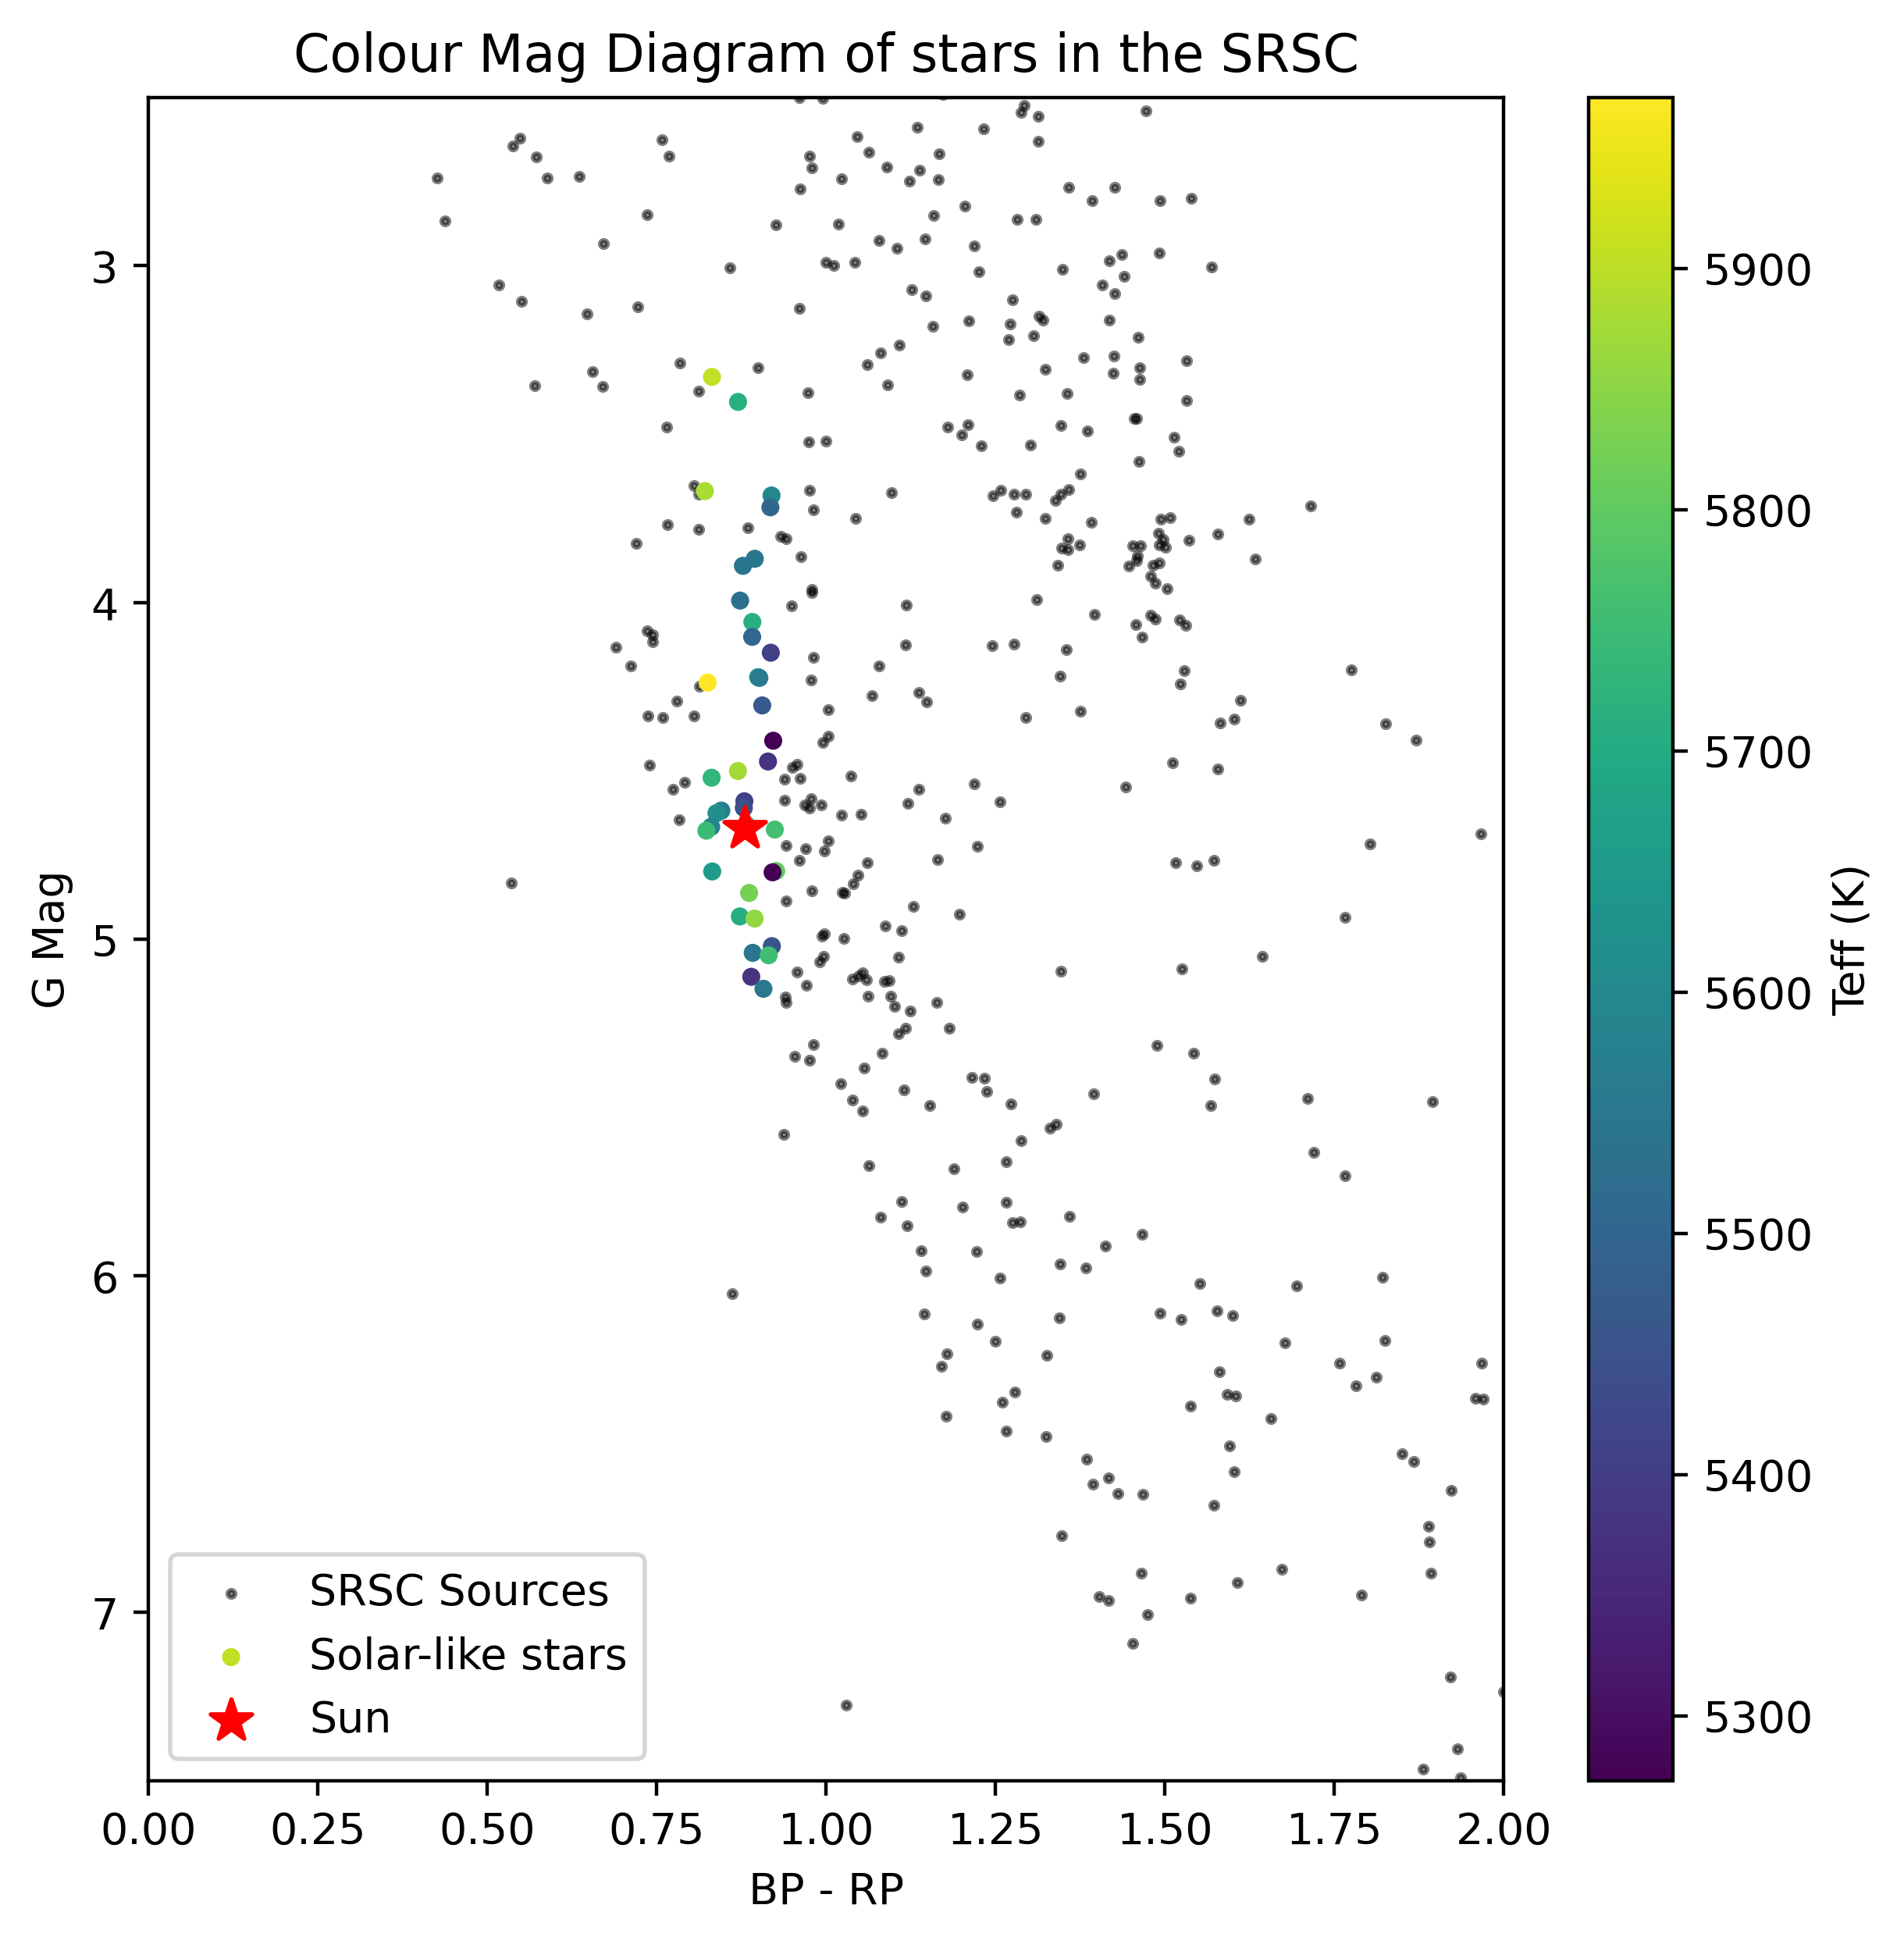

<Figure size 640x480 with 0 Axes>

In [46]:
plt.figure(figsize=(7,7), dpi=400)
plt.scatter(srsc_stars['bp_rp'], srsc_stars['abs_mag'], s=3, c='black', alpha = 0.5, label='SRSC Sources')
sc = plt.scatter(solar_like_stars['bp_rp'], solar_like_stars['abs_mag'], s=10, c=solar_like_stars['teff_gspphot'], cmap='viridis', label = 'Solar-like stars')


plt.scatter(0.88, 4.67, c='red', marker='*', s=100, label='Sun') # Golovin 2023

plt.ylim(7.5, 2.5)
plt.xlim(-0,2)
plt.xlabel('BP - RP')
plt.ylabel('G Mag')
plt.title('Colour Mag Diagram of stars in the SRSC')

cbar = plt.colorbar(sc)
cbar.set_label('Teff (K)')

plt.legend()
plt.show()
plt.savefig('figures/solar_like_stars_cmd.png')

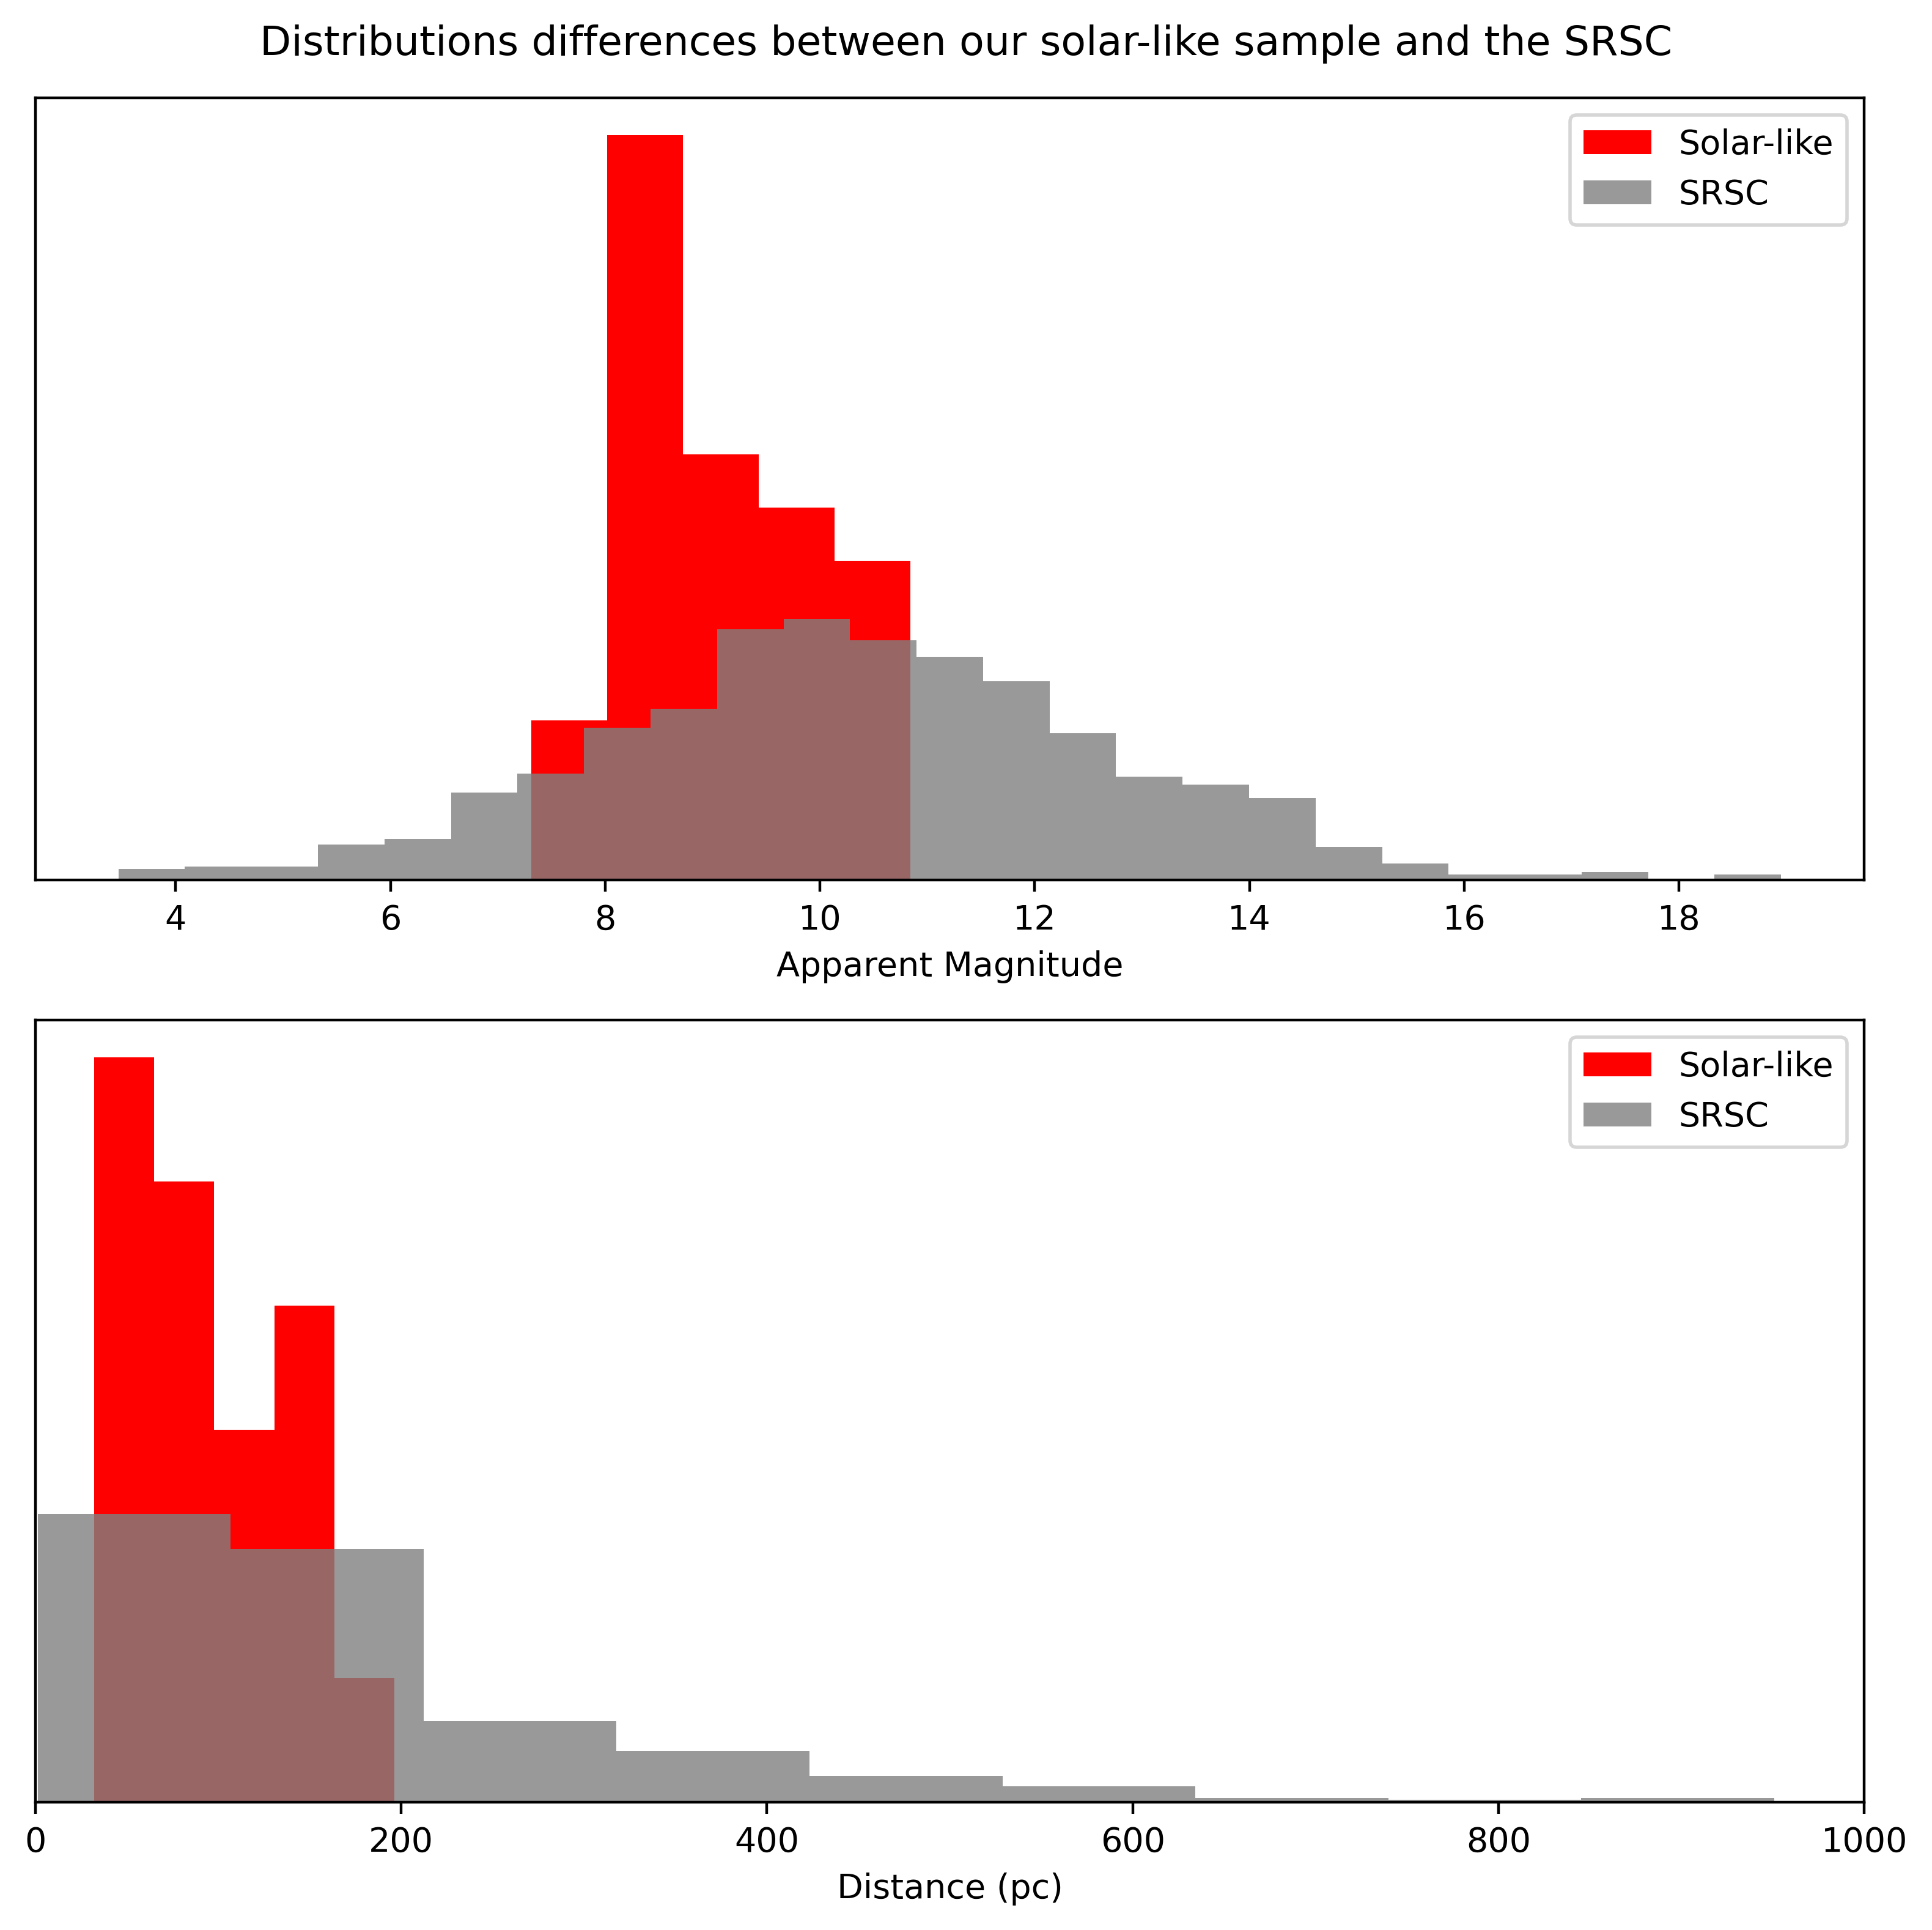

<Figure size 640x480 with 0 Axes>

In [38]:
fig, axes = plt.subplots(2,1, figsize=(8,8), dpi=400)

axes[0].hist(solar_like_stars['phot_g_mean_mag'], bins=5, density=True,
             color='red', label='Solar-like')
axes[0].hist(srsc_stars['phot_g_mean_mag'], bins=25, density=True,
             color='gray', alpha=0.8, label='SRSC')
axes[0].set_xlabel('Apparent Magnitude')
axes[0].get_yaxis().set_visible(False)
axes[0].legend()

axes[1].hist(solar_like_stars['r_med_geo'], bins=5, density=True,
             color='red', label='Solar-like')
axes[1].hist(srsc_stars['r_med_geo'], bins=50, density=True,
             color='gray', alpha=0.8, label='SRSC')
axes[1].set_xlabel('Distance (pc)')
axes[1].set_xlim(0,1000)
axes[1].get_yaxis().set_visible(False)
axes[1].legend()

fig.suptitle('Distributions differences between our solar-like sample and the SRSC')
plt.tight_layout()
plt.show()
plt.savefig('figures/solar_like_distribution.png')

In [31]:
query = """
SELECT TOP 10000
    source_id,
    phot_g_mean_mag,
    bp_rp,
    parallax
FROM gaiadr3.gaia_source
WHERE phot_g_mean_mag IS NOT NULL
  AND bp_rp IS NOT NULL
  AND parallax > 0
  AND parallax_over_error > 10
"""

In [32]:
job = Gaia.launch_job_async(query)
data = job.get_results()

INFO: Query finished. [astroquery.utils.tap.core]


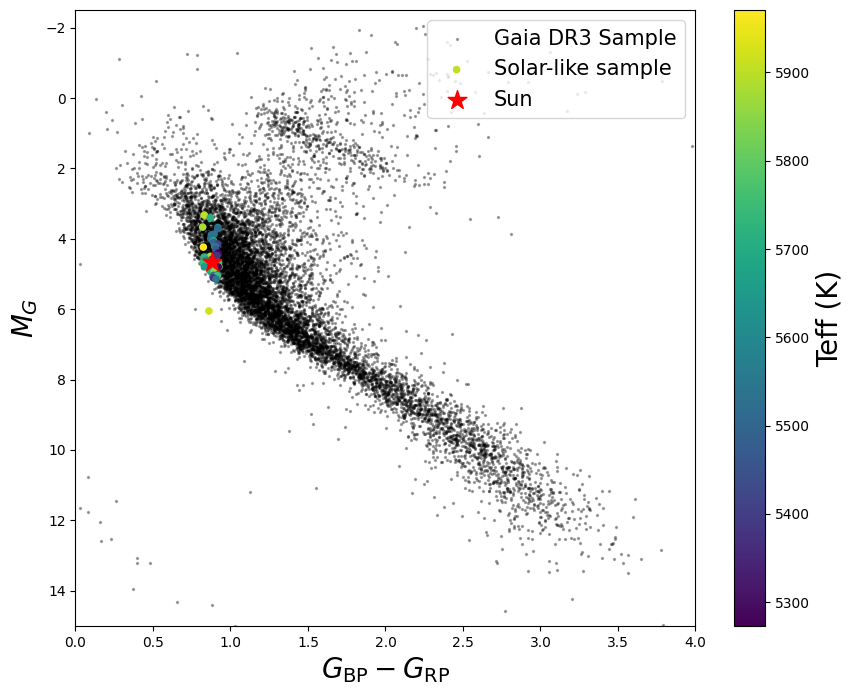

In [34]:
# Absolute G magnitude
data['M_G'] = (
    data['phot_g_mean_mag']
    + 5 * np.log10(data['parallax'] / 1000)
    + 5
)

plt.figure(figsize=(10, 8))

plt.scatter(
    data['bp_rp'],
    data['M_G'],
    s=2,
    alpha=0.3,
    c = 'black',
    label = 'Gaia DR3 Sample'
)
sc = plt.scatter(solar_like_stars['bp_rp'], solar_like_stars['abs_mag'], s=20, c=solar_like_stars['teff_gspphot'], cmap='viridis', label = 'Solar-like sample')
plt.scatter(0.88, 4.67, c='red', marker='*', s=200, label='Sun') 


plt.gca().invert_yaxis()

plt.xlabel(r'$G_{\rm BP} - G_{\rm RP}$',fontsize=20)
plt.ylabel(r'$M_G$',fontsize=20)
# plt.title('Gaia DR3 Colour–Magnitude Diagram',fontsize=20)
cbar = plt.colorbar(sc)
cbar.set_label('Teff (K)', fontsize=20)

plt.xlim(0,4)
plt.ylim(15,-2.5)

plt.legend(fontsize=15, loc = 'upper right')
plt.savefig(r'C:\Users\josh1\Desktop\Projects\Honours\thesis_figures\solar-cmd.pdf', dpi=300, bbox_inches='tight')
plt.show()

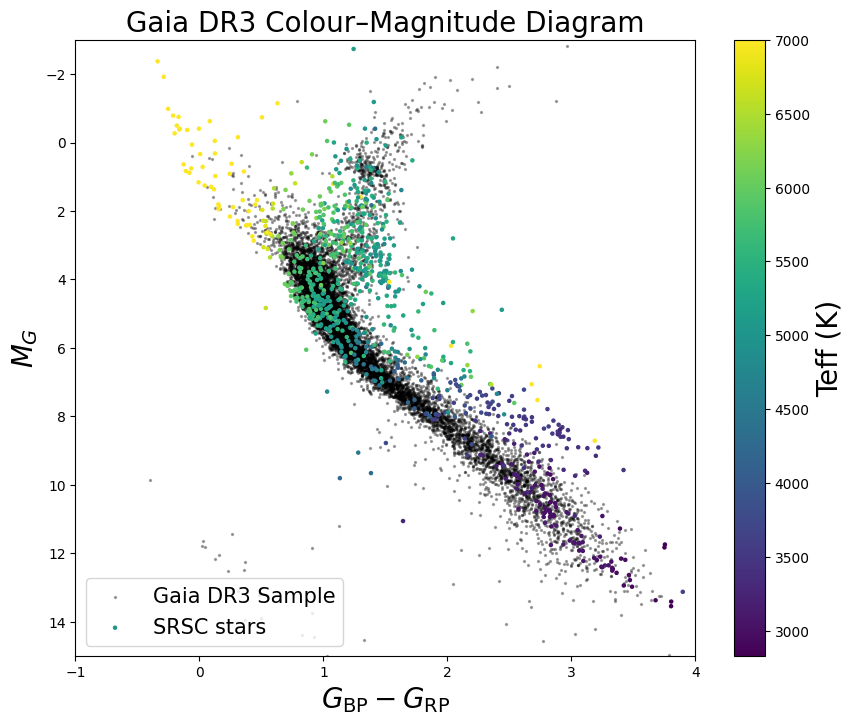

In [46]:
# Absolute G magnitude
data['M_G'] = (
    data['phot_g_mean_mag']
    + 5 * np.log10(data['parallax'] / 1000)
    + 5
)

plt.figure(figsize=(10, 8))

plt.scatter(
    data['bp_rp'],
    data['M_G'],
    s=2,
    alpha=0.3,
    c = 'black',
    label = 'Gaia DR3 Sample'
)
sc = plt.scatter(srsc_stars['bp_rp'], srsc_stars['abs_mag'], s=5, c=srsc_stars['teff_gspphot'], vmax=7000, cmap='viridis', label = 'SRSC stars')
# plt.scatter(0.88, 4.67, c='red', marker='*', s=200, label='Sun') 


plt.gca().invert_yaxis()

plt.xlabel(r'$G_{\rm BP} - G_{\rm RP}$',fontsize=20)
plt.ylabel(r'$M_G$',fontsize=20)
plt.title('Gaia DR3 Colour–Magnitude Diagram',fontsize=20)
cbar = plt.colorbar(sc)
cbar.set_label('Teff (K)', fontsize=20)

plt.xlim(-1,4)
plt.ylim(15,-3)

plt.legend(fontsize=15, loc = 'lower left')
plt.savefig(r'C:\Users\josh1\Desktop\Projects\Honours\thesis_figures\srsc-cmd.png', dpi=300, bbox_inches='tight')
plt.show()

In [36]:
data['distance_pc'] = 1000 / data['parallax']

(array([3.244e+03, 3.769e+03, 2.101e+03, 6.010e+02, 1.620e+02, 5.500e+01,
        3.400e+01, 2.000e+01, 1.300e+01, 1.000e+00]),
 array([  31.31683868,  640.63995065, 1249.96306263, 1859.28617461,
        2468.60928659, 3077.93239857, 3687.25551055, 4296.57862252,
        4905.9017345 , 5515.22484648, 6124.54795846]),
 <BarContainer object of 10 artists>)

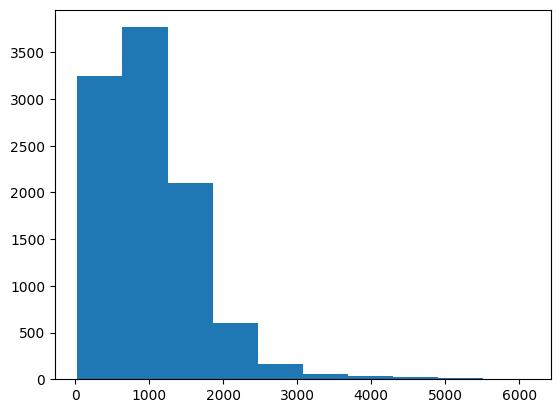

In [55]:
plt.hist(data['distance_pc'])

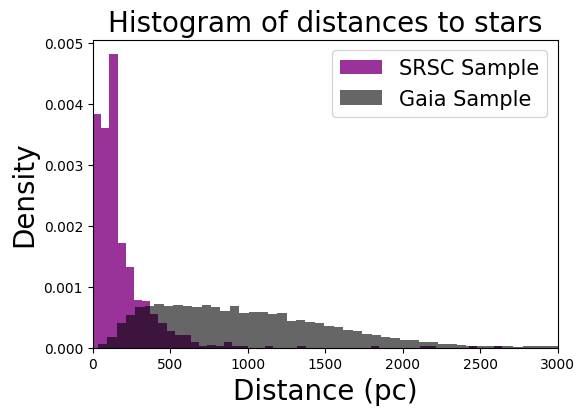

In [59]:
distance = data['distance_pc'].value
sample_dist = solar_like_stars['r_med_geo'].value
srsc_dist = srsc_stars['r_med_geo'].value

plt.figure(figsize = (6,4))
# plt.hist(sample_dist, bins = 10, density=True, color = 'darkorange', edgecolor='black', label = 'Solar-like sample')
plt.hist(srsc_dist, bins=100, density=True, color = 'purple', alpha = 0.8, label = 'SRSC Sample')
plt.hist(distance, bins = 100, density=True, color = 'black', alpha=0.6, label = 'Gaia Sample')
plt.xlim(0,3000)

plt.xlabel('Distance (pc)', fontsize = 20)
plt.ylabel('Density', fontsize = 20)
plt.title('Histogram of distances to stars',fontsize=20)
plt.legend(fontsize = 15)
plt.show()

In [72]:
sample_dist.max()

np.float64(196.45445251464844)

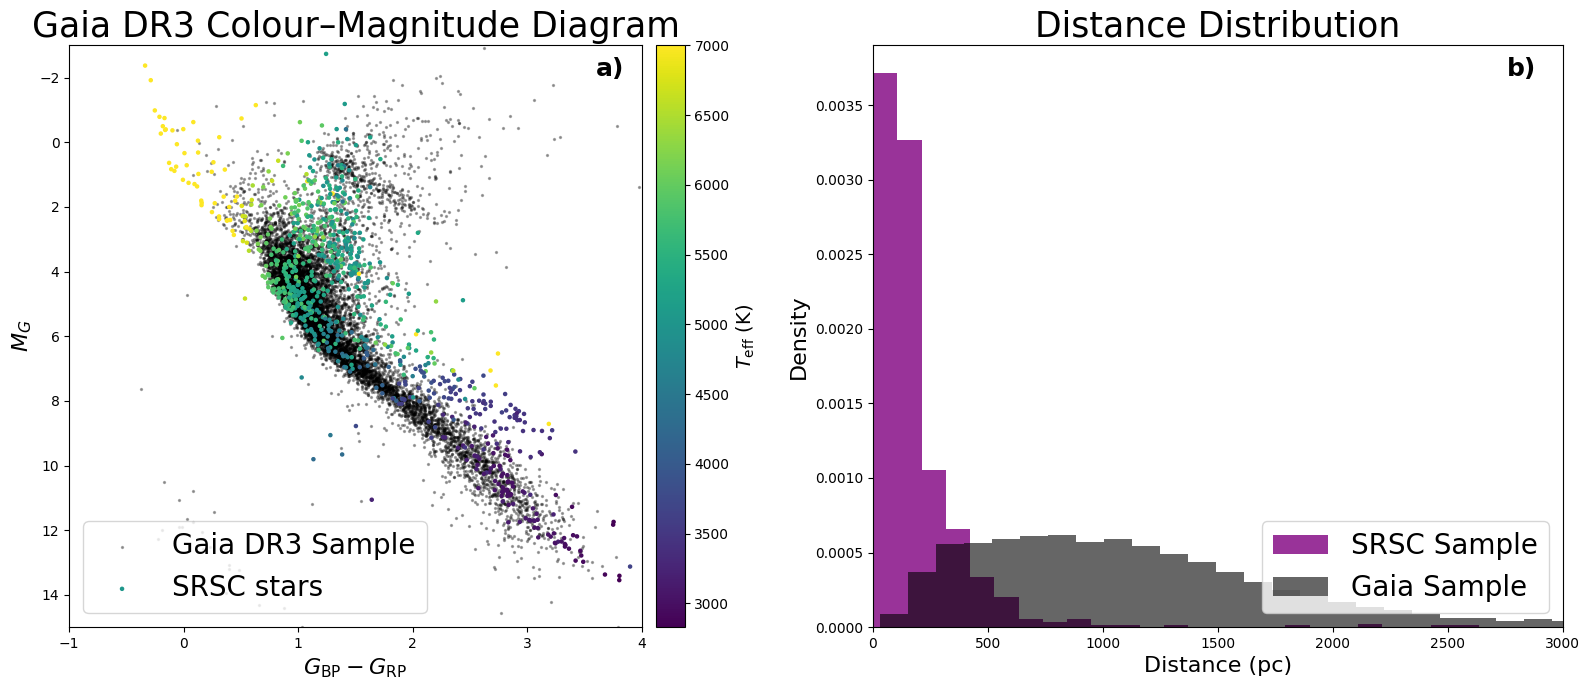

In [39]:
# Absolute G magnitude
data['M_G'] = (
    data['phot_g_mean_mag']
    + 5 * np.log10(data['parallax'] / 1000)
    + 5
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# --- Left: Colour–Magnitude Diagram ---
ax1.scatter(
    data['bp_rp'],
    data['M_G'],
    s=2,
    alpha=0.3,
    c='black',
    label='Gaia DR3 Sample'
)

sc = ax1.scatter(
    srsc_stars['bp_rp'],
    srsc_stars['abs_mag'],
    s=5,
    c=srsc_stars['teff_gspphot'],
    vmax=7000,
    cmap='viridis',
    label='SRSC stars'
)

ax1.invert_yaxis()
ax1.set_xlabel(r'$G_{\rm BP} - G_{\rm RP}$', fontsize=16)
ax1.set_ylabel(r'$M_G$', fontsize=16)
ax1.set_title('Gaia DR3 Colour–Magnitude Diagram', fontsize=25)
ax1.set_xlim(-1, 4)
ax1.set_ylim(15, -3)
ax1.legend(fontsize=20, loc='lower left')

cbar = fig.colorbar(sc, ax=ax1, pad=0.02)
cbar.set_label(r'$T_{\rm eff}$ (K)', fontsize=14)

# --- Right: Distance Distribution ---
distance = data['distance_pc'].value
srsc_dist = srsc_stars['r_med_geo'].value

ax2.hist(
    srsc_dist,
    bins=50,
    density=True,
    color='purple',
    alpha=0.8,
    label='SRSC Sample'
)

ax2.hist(
    distance,
    bins=50,
    density=True,
    color='black',
    alpha=0.6,
    label='Gaia Sample'
)

ax2.set_xlim(0, 3000)
ax2.set_xlabel('Distance (pc)', fontsize=16)
ax2.set_ylabel('Density', fontsize=16)
ax2.set_title('Distance Distribution', fontsize=25)
ax2.legend(fontsize=20, loc = 'lower right')

ax1.text(0.92, 0.98, 'a)', transform=ax1.transAxes,
         fontsize=18, fontweight='bold', va='top')

ax2.text(0.92, 0.98, 'b)', transform=ax2.transAxes,
         fontsize=18, fontweight='bold', va='top')

plt.tight_layout()

plt.savefig(r'C:\Users\josh1\Desktop\Projects\Honours\thesis_figures\srsc-cmd.pdf', dpi=300, bbox_inches='tight')

plt.show()